# EcoGrid Analytics — Entrenamiento del primer modelo de demanda

**Objetivo:** predecir la demanda eléctrica peninsular agregada de REE (`demanda_real`, MW) para las próximas 24 horas.

Este notebook está preparado a partir de `training_dataset_2023-11-08_2026-11-08_V2.csv`.

### Decisiones metodológicas
- Se conserva `demanda_real` sin interpolar: las filas sin objetivo válido no se usan para entrenar ni evaluar.
- Se excluyen inicialmente meteorología, precios y previsiones REE. La meteorología del histórico son observaciones reales, no previsiones archivadas; utilizarlas para horas futuras produciría fuga de información.
- Se utilizan calendario y retardos de demanda conocidos al emitir la predicción: 24 y 168 horas.
- El baseline es persistencia diaria: demanda real de la misma hora del día anterior.
- División cronológica 70 % entrenamiento, 15 % validación y 15 % prueba. El test se reserva para la evaluación final.
- Se entrena un XGBoost de un paso horario y se generan 24 predicciones independientes, usando retardos observados disponibles en el momento de emisión.

**Importante:** el CSV contiene `time` en UTC. Las fechas que se muestran en el dashboard pueden convertirse después a `Europe/Madrid`.

## 1. Instalar e importar librerías

En Colab, ejecuta esta celda al principio. Si Colab solicita reiniciar el entorno después de instalar XGBoost, reinícialo y vuelve a ejecutar desde arriba.

In [15]:
%pip -q install -U xgboost joblib

import os
import json
import warnings
from pathlib import Path
from datetime import timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
print("XGBoost:", xgb.__version__)
print("Pandas:", pd.__version__)

XGBoost: 3.4.1
Pandas: 2.2.3


## 2. Cargar el CSV V2

Sube `training_dataset_2023-11-08_2026-11-08_V2.csv` a Colab cuando aparezca el selector. También puedes cambiar `CSV_PATH` si lo tienes en Google Drive.

In [28]:
from google.colab import files

CSV_PATH = "/content/training_dataset_2023-11-08_2026-11-08_V2.csv"

if not os.path.exists(CSV_PATH):
    print("Selecciona el archivo training_dataset_2023-11-08_2026-11-08_V2.csv")
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No se ha subido ningún CSV.")
    uploaded_name = next(iter(uploaded))
    CSV_PATH = f"/content/{uploaded_name}"

df_raw = pd.read_csv(CSV_PATH)

required = {"time", "demanda_real"}
missing = required - set(df_raw.columns)
if missing:
    raise ValueError(f"Faltan columnas obligatorias: {missing}")

df_raw["time"] = pd.to_datetime(df_raw["time"], errors="coerce", utc=True)
df_raw = df_raw.dropna(subset=["time"]).sort_values("time").reset_index(drop=True)

print("Dimensiones:", df_raw.shape)
print("Periodo UTC:", df_raw["time"].min(), "->", df_raw["time"].max())
display(df_raw.head())

Dimensiones: (26304, 25)
Periodo UTC: 2023-11-07 23:00:00+00:00 -> 2026-11-07 22:00:00+00:00


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_speed_80m,wind_speed_120m,wind_speed_180m,wind_direction_10m,wind_direction_80m,wind_direction_120m,wind_direction_180m,cloud_cover,direct_normal_irradiance,global_tilted_irradiance,shortwave_radiation,year,month,day,hour,price_spain,price_portugal,demanda_prevista,demanda_programada,demanda_real,demanda_programada total
0,2023-11-07 23:00:00+00:00,5.4,93,2.02,4.99,5.22,NaN,261,266,266,NaN,96,0.0,0.0,0.0,2023,11,7,23,93.35,93.35,25604.750000,25641.0,25713.166667,NaN
1,2023-11-08 00:00:00+00:00,4.5,96,1.90,4.03,4.22,NaN,267,263,263,NaN,100,0.0,0.0,0.0,2023,11,8,0,79.39,79.39,24071.333333,24089.5,24072.250000,NaN
2,2023-11-08 01:00:00+00:00,4.5,95,1.42,3.62,3.79,NaN,231,246,246,NaN,100,0.0,0.0,0.0,2023,11,8,1,77.99,77.99,23168.083333,23192.5,23225.000000,NaN
3,2023-11-08 02:00:00+00:00,4.8,96,1.30,3.62,3.79,NaN,270,256,256,NaN,100,0.0,0.0,0.0,2023,11,8,2,76.30,76.30,22709.250000,22743.5,22774.416667,NaN
4,2023-11-08 03:00:00+00:00,4.9,97,1.10,3.08,3.22,NaN,275,259,259,NaN,96,0.0,0.0,0.0,2023,11,8,3,66.76,66.76,22689.000000,22667.0,22775.666667,NaN


## 3. Auditoría de calidad

Esta celda no rellena el objetivo ni crea datos artificiales. Comprueba duplicados, continuidad horaria y valores ausentes.

In [17]:
print("Duplicados de timestamp:", df_raw["time"].duplicated().sum())
print("\nNulos por columna:")
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("nulos").head(15))

# Consolidar duplicados temporales si existieran, usando la media numérica.
if df_raw["time"].duplicated().any():
    numeric_cols = df_raw.select_dtypes(include=np.number).columns.tolist()
    agg = {c: "mean" for c in numeric_cols}
    df_raw = df_raw.groupby("time", as_index=False).agg(agg)

# Verificar huecos del índice horario esperado.
full_hours = pd.date_range(df_raw["time"].min(), df_raw["time"].max(), freq="h", tz="UTC")
observed_hours = pd.DatetimeIndex(df_raw["time"])
missing_timestamps = full_hours.difference(observed_hours)
print("\nHoras ausentes en la serie temporal:", len(missing_timestamps))
if len(missing_timestamps):
    print("Primeras horas ausentes:", list(missing_timestamps[:10]))

# No se imputan la demanda real ni los retardos.
print("\nNulos en demanda_real:", df_raw["demanda_real"].isna().sum())

Duplicados de timestamp: 0

Nulos por columna:


,nulos
wind_speed_180m,26304
wind_direction_180m,26304
demanda_programada total,18336
price_spain,48
price_portugal,48
demanda_real,46
time,0
wind_speed_10m,0
temperature_2m,0
wind_direction_80m,0



Horas ausentes en la serie temporal: 0

Nulos en demanda_real: 46


## 4. Preparar la serie y crear variables

Se trabaja con una rejilla horaria UTC. Los huecos de timestamp se insertan como filas vacías para que `shift(24)` y `shift(168)` representen exactamente 24 y 168 horas, sin desplazar datos a través de huecos.

Las variables meteorológicas y de mercado se dejan fuera en esta primera versión para evitar utilizar observaciones futuras que no estarían disponibles en producción.

In [18]:
# Dataset de trabajo con una fila por cada hora del intervalo.
df = df_raw.set_index("time").sort_index()
df = df[~df.index.duplicated(keep="first")]

hourly_index = pd.date_range(df.index.min(), df.index.max(), freq="h", tz="UTC")
df = df.reindex(hourly_index)
df.index.name = "time"

# Convertir el objetivo a numérico sin imputarlo.
df["demanda_real"] = pd.to_numeric(df["demanda_real"], errors="coerce")

# Variables de calendario de la hora objetivo.
df_model = pd.DataFrame(index=df.index)
df_model["target"] = df["demanda_real"]
df_model["hour"] = df_model.index.hour
df_model["dayofweek"] = df_model.index.dayofweek
df_model["month"] = df_model.index.month
df_model["dayofyear"] = df_model.index.dayofyear

# Codificación cíclica de calendario.
df_model["hour_sin"] = np.sin(2 * np.pi * df_model["hour"] / 24)
df_model["hour_cos"] = np.cos(2 * np.pi * df_model["hour"] / 24)
df_model["dow_sin"] = np.sin(2 * np.pi * df_model["dayofweek"] / 7)
df_model["dow_cos"] = np.cos(2 * np.pi * df_model["dayofweek"] / 7)
df_model["year_sin"] = np.sin(2 * np.pi * df_model["dayofyear"] / 365.25)
df_model["year_cos"] = np.cos(2 * np.pi * df_model["dayofyear"] / 365.25)

# Retardos: solo valores de demanda ya observados en la hora de predicción.
df_model["lag_24h"] = df_model["target"].shift(24)
df_model["lag_168h"] = df_model["target"].shift(168)

# El baseline se define igual que la persistencia de 24 horas.
df_model["baseline_24h"] = df_model["lag_24h"]

FEATURES = [
    "hour", "dayofweek", "month", "dayofyear",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "year_sin", "year_cos",
    "lag_24h", "lag_168h"
]
TARGET = "target"

model_data = df_model.dropna(subset=[TARGET] + FEATURES).copy()

print("Filas válidas para modelado:", len(model_data))
print("Columnas de entrada:", FEATURES)
print("Periodo utilizable:", model_data.index.min(), "->", model_data.index.max())
display(model_data[FEATURES + [TARGET, "baseline_24h"]].head())

Filas válidas para modelado: 26006
Columnas de entrada: ['hour', 'dayofweek', 'month', 'dayofyear', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'year_sin', 'year_cos', 'lag_24h', 'lag_168h']
Periodo utilizable: 2023-11-14 23:00:00+00:00 -> 2026-11-07 22:00:00+00:00


,hour,dayofweek,month,dayofyear,hour_sin,hour_cos,dow_sin,dow_cos,year_sin,year_cos,lag_24h,lag_168h,target,baseline_24h
time,,,,,,,,,,,,,,
2023-11-14 23:00:00+00:00,23,1,11,318,-0.258819,0.965926,0.781831,0.623490,-0.726225,0.687457,25008.916667,25713.166667,24987.583333,25008.916667
2023-11-15 00:00:00+00:00,0,2,11,319,0.000000,1.000000,0.974928,-0.222521,-0.714292,0.699848,23674.333333,24072.250000,23617.500000,23674.333333
2023-11-15 01:00:00+00:00,1,2,11,319,0.258819,0.965926,0.974928,-0.222521,-0.714292,0.699848,22773.500000,23225.000000,22773.083333,22773.500000
2023-11-15 02:00:00+00:00,2,2,11,319,0.500000,0.866025,0.974928,-0.222521,-0.714292,0.699848,22264.333333,22774.416667,22421.583333,22264.333333
2023-11-15 03:00:00+00:00,3,2,11,319,0.707107,0.707107,0.974928,-0.222521,-0.714292,0.699848,22185.750000,22775.666667,22336.583333,22185.750000


## 5. Separación cronológica: train / validation / test

No se barajan las filas. El conjunto de prueba es el tramo más reciente y no se utiliza para elegir hiperparámetros.

In [19]:
n = len(model_data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_data.iloc[:train_end].copy()
val_df = model_data.iloc[train_end:val_end].copy()
test_df = model_data.iloc[val_end:].copy()

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_val, y_val = val_df[FEATURES], val_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

print(f"Train: {len(train_df):,} | {train_df.index.min()} -> {train_df.index.max()}")
print(f"Validación: {len(val_df):,} | {val_df.index.min()} -> {val_df.index.max()}")
print(f"Test: {len(test_df):,} | {test_df.index.min()} -> {test_df.index.max()}")

Train: 18,204 | 2023-11-14 23:00:00+00:00 -> 2025-12-16 02:00:00+00:00
Validación: 3,901 | 2025-12-16 03:00:00+00:00 -> 2026-05-27 15:00:00+00:00
Test: 3,901 | 2026-05-27 16:00:00+00:00 -> 2026-11-07 22:00:00+00:00


## 6. Evaluar el baseline de persistencia

La predicción de referencia para cada hora es la demanda observada exactamente 24 horas antes. El baseline y el modelo se comparan sobre las mismas filas.

In [20]:
def calculate_metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    # MAPE solo como métrica secundaria; demanda debe ser positiva.
    mape = np.mean(np.abs((np.asarray(y_true) - np.asarray(y_pred)) / np.asarray(y_true))) * 100
    return {"modelo": name, "MAE_MW": mae, "RMSE_MW": rmse, "MAPE_pct": mape}

baseline_val = calculate_metrics(y_val, val_df["baseline_24h"], "Baseline - validación")
baseline_test = calculate_metrics(y_test, test_df["baseline_24h"], "Baseline - test")

display(pd.DataFrame([baseline_val, baseline_test]).round(3))

,modelo,MAE_MW,RMSE_MW,MAPE_pct
0,Baseline - validación,1879.545,2849.250,6.247
1,Baseline - test,1972.475,2915.716,6.092


## 7. Entrenar XGBoost

Configuración inicial equilibrada para este tamaño de dataset. Se usa CPU (`tree_method='hist'`), que suele ser suficiente para unas decenas de miles de filas. La GPU de Colab no garantiza una mejora apreciable para este problema.

In [21]:
model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=700,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.90,
    reg_alpha=0.0,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="mae",
    early_stopping_rounds=60,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=100
)

print("Mejor iteración:", getattr(model, "best_iteration", None))

[0]	validation_0-mae:4570.44305
[100]	validation_0-mae:947.35325
[200]	validation_0-mae:870.55630
[300]	validation_0-mae:870.82282
[355]	validation_0-mae:877.87368
Mejor iteración: 295


## 8. Evaluación final en el test

El conjunto de prueba se consulta ahora, una vez entrenado el modelo. Si el XGBoost no supera al baseline, no se debe presentar como una mejora: habrá que revisar variables y metodología.

In [22]:
pred_val = model.predict(X_val)
pred_test = model.predict(X_test)

results = pd.DataFrame([
    calculate_metrics(y_val, val_df["baseline_24h"], "Baseline - validación"),
    calculate_metrics(y_val, pred_val, "XGBoost - validación"),
    calculate_metrics(y_test, test_df["baseline_24h"], "Baseline - test"),
    calculate_metrics(y_test, pred_test, "XGBoost - test")
])

display(results.round(3))

mae_base_test = mean_absolute_error(y_test, test_df["baseline_24h"])
mae_model_test = mean_absolute_error(y_test, pred_test)
improvement = (mae_base_test - mae_model_test) / mae_base_test * 100

print(f"Mejora de MAE frente al baseline en test: {improvement:.2f}%")
if improvement > 0:
    print("El modelo mejora el baseline en el conjunto de prueba.")
else:
    print("ATENCIÓN: el modelo no mejora el baseline en test. No lo presentes como superior.")

,modelo,MAE_MW,RMSE_MW,MAPE_pct
0,Baseline - validación,1879.545,2849.250,6.247
1,XGBoost - validación,868.244,1314.481,2.857
2,Baseline - test,1972.475,2915.716,6.092
3,XGBoost - test,1283.211,1900.542,3.615


Mejora de MAE frente al baseline en test: 34.94%
El modelo mejora el baseline en el conjunto de prueba.


## 9. Visualizar el tramo de prueba

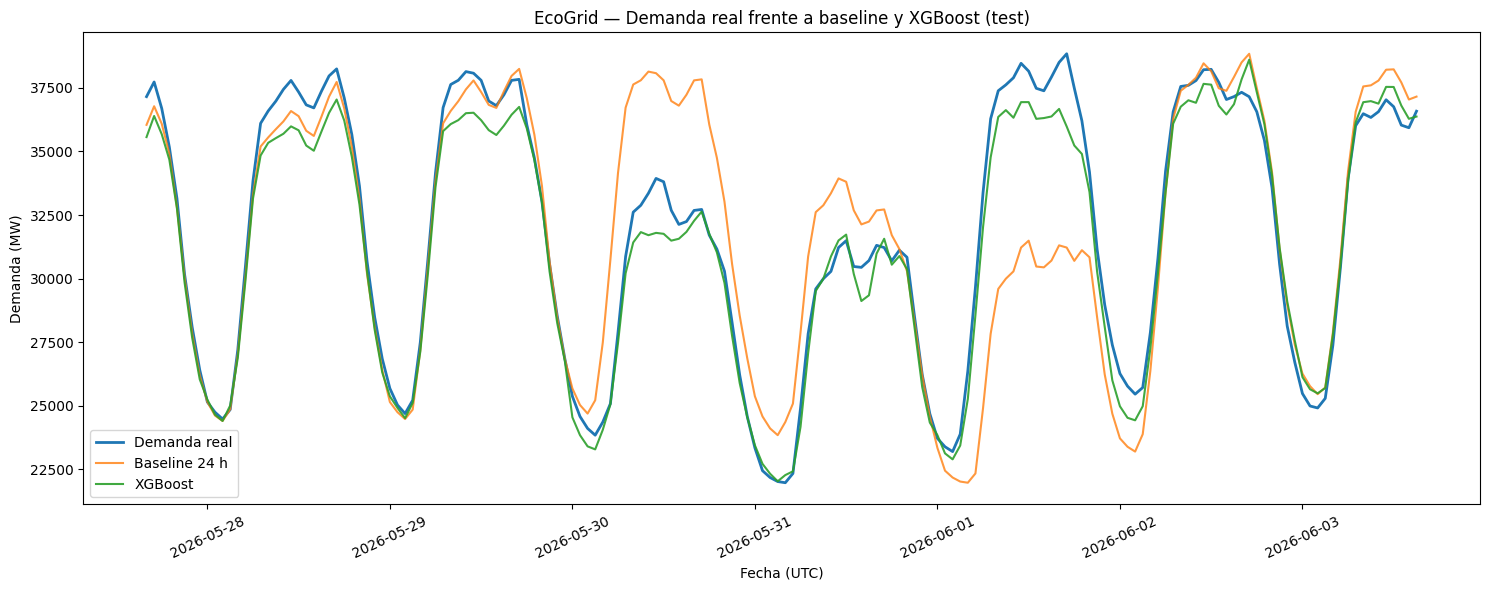

In [23]:
plot_n = min(24 * 7, len(test_df))
plot_df = test_df.iloc[:plot_n]

plt.figure(figsize=(15, 6))
plt.plot(plot_df.index, plot_df[TARGET], label="Demanda real", linewidth=2)
plt.plot(plot_df.index, plot_df["baseline_24h"], label="Baseline 24 h", alpha=0.8)
plt.plot(plot_df.index, model.predict(plot_df[FEATURES]), label="XGBoost", alpha=0.9)
plt.title("EcoGrid — Demanda real frente a baseline y XGBoost (test)")
plt.xlabel("Fecha (UTC)")
plt.ylabel("Demanda (MW)")
plt.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 10. Entrenar el modelo de producción y guardar artefactos

Una vez medida la calidad en el test, se crea un modelo de producción con los datos históricos válidos disponibles (train + validación + test). Las métricas de test anteriores siguen siendo la evaluación independiente del procedimiento anterior; el modelo de producción se entrena para aprovechar todo el histórico.

Se guardan:
- `modelo_xgboost_demanda.joblib`
- `features_modelo.json`
- `metricas_evaluacion.json`

In [24]:
production_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=(getattr(model, "best_iteration", None) + 1)
        if getattr(model, "best_iteration", None) is not None else 700,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.90,
    reg_alpha=0.0,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="mae",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

X_all, y_all = model_data[FEATURES], model_data[TARGET]
production_model.fit(X_all, y_all, verbose=False)

os.makedirs("/content/ecogrid_model", exist_ok=True)
MODEL_PATH = "/content/ecogrid_model/modelo_xgboost_demanda.joblib"
FEATURES_PATH = "/content/ecogrid_model/features_modelo.json"
METRICS_PATH = "/content/ecogrid_model/metricas_evaluacion.json"

joblib.dump(production_model, MODEL_PATH)

with open(FEATURES_PATH, "w", encoding="utf-8") as f:
    json.dump(FEATURES, f, ensure_ascii=False, indent=2)

metrics_dict = {
    "target": "demanda_real",
    "target_unit": "MW",
    "horizon_hours": 24,
    "timezone_dataset": "UTC",
    "features": FEATURES,
    "train_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "test_rows": int(len(test_df)),
    "baseline_test": baseline_test,
    "xgboost_test": calculate_metrics(y_test, pred_test, "XGBoost - test"),
    "mae_improvement_pct_test": float(improvement),
    "best_iteration_validation": int(getattr(model, "best_iteration", -1))
}
with open(METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(metrics_dict, f, ensure_ascii=False, indent=2)

print("Modelo guardado:", MODEL_PATH)
print("Variables guardadas:", FEATURES_PATH)
print("Métricas guardadas:", METRICS_PATH)

Modelo guardado: /content/ecogrid_model/modelo_xgboost_demanda.joblib
Variables guardadas: /content/ecogrid_model/features_modelo.json
Métricas guardadas: /content/ecogrid_model/metricas_evaluacion.json


## 11. Generar las próximas 24 horas

Este bloque utiliza los últimos valores reales observados para calcular los retardos de 24 y 168 horas. No necesita ni utiliza meteorología observada futura.

**Condición:** para que la inferencia sea válida, el histórico debe terminar en la última hora real disponible y debe contener los valores necesarios para los retardos. En un uso operativo, sustituye el histórico por los datos actualizados de REE.

In [25]:
# Recuperar la serie de demanda real observada.
history = df["demanda_real"].dropna().sort_index()

if history.empty:
    raise ValueError("No hay valores válidos de demanda_real para generar predicciones.")

last_observed_time = history.index.max()
last_value_time = df.index.max()

if last_observed_time != last_value_time:
    print(
        "AVISO: la última fila del dataset no tiene demanda real. "
        "La predicción partirá de la última hora con dato real:",
        last_observed_time
    )

# Crear las 24 horas posteriores al último dato real disponible.
# El índice del dataset está en UTC.
future_times = pd.date_range(
    start=last_observed_time + pd.Timedelta(hours=1),
    periods=24,
    freq="h"
)

# Para cada hora futura t, el modelo necesita demanda_real(t-24h) y demanda_real(t-168h).
# Son dos bloques de 24 valores; no hace falta que todas las horas intermedias estén completas.
lag24_times = future_times - pd.Timedelta(hours=24)
lag168_times = future_times - pd.Timedelta(hours=168)

actual_demand = df["demanda_real"]
lag24_values = actual_demand.reindex(lag24_times)
lag168_values = actual_demand.reindex(lag168_times)

missing_lag24 = lag24_values[lag24_values.isna()].index
missing_lag168 = lag168_values[lag168_values.isna()].index

if len(missing_lag24) or len(missing_lag168):
    details = []
    if len(missing_lag24):
        details.append(
            "Faltan valores para lag_24h en: " +
            ", ".join(str(t) for t in missing_lag24)
        )
    if len(missing_lag168):
        details.append(
            "Faltan valores para lag_168h en: " +
            ", ".join(str(t) for t in missing_lag168)
        )
    raise ValueError(
        "No se pueden generar las 24 predicciones sin esos valores reales. "
        "Recupera las observaciones faltantes de REE; no se imputan automáticamente.\n" +
        "\n".join(details)
    )

# Avisar si el histórico está desactualizado respecto al momento de ejecución.
now_utc = pd.Timestamp.now(tz="UTC")
if last_observed_time < now_utc - pd.Timedelta(hours=2):
    print(
        "ADVERTENCIA: el último dato real disponible es",
        last_observed_time,
        "UTC. Las predicciones generadas serán posteriores a ese dato, "
        "pero el periodo puede estar ya en el pasado. Para una predicción operativa, "
        "actualiza primero el histórico con los datos recientes de REE."
    )

future = pd.DataFrame(index=future_times)
future["hour"] = future.index.hour
future["dayofweek"] = future.index.dayofweek
future["month"] = future.index.month
future["dayofyear"] = future.index.dayofyear
future["hour_sin"] = np.sin(2 * np.pi * future["hour"] / 24)
future["hour_cos"] = np.cos(2 * np.pi * future["hour"] / 24)
future["dow_sin"] = np.sin(2 * np.pi * future["dayofweek"] / 7)
future["dow_cos"] = np.cos(2 * np.pi * future["dayofweek"] / 7)
future["year_sin"] = np.sin(2 * np.pi * future["dayofyear"] / 365.25)
future["year_cos"] = np.cos(2 * np.pi * future["dayofyear"] / 365.25)

# Asignar los retardos comprobados, sin rellenar valores ausentes.
future["lag_24h"] = lag24_values.to_numpy()
future["lag_168h"] = lag168_values.to_numpy()
future["baseline_24h"] = future["lag_24h"]

# Generar predicción XGBoost y baseline para cada una de las 24 horas.
future["demanda_predicha_mw"] = production_model.predict(future[FEATURES])
future["demanda_baseline_mw"] = future["baseline_24h"].values
future["fecha_ejecucion_utc"] = now_utc

predictions_24h = future.reset_index(names="time")
predictions_24h["time"] = predictions_24h["time"].astype(str)
predictions_24h["fecha_ejecucion_utc"] = predictions_24h["fecha_ejecucion_utc"].astype(str)

display(predictions_24h[[
    "time", "demanda_predicha_mw", "demanda_baseline_mw", "fecha_ejecucion_utc"
]])

ADVERTENCIA: el último dato real disponible es 2026-11-07 22:00:00+00:00 UTC. Las predicciones generadas serán posteriores a ese dato, pero el periodo puede estar ya en el pasado. Para una predicción operativa, actualiza primero el histórico con los datos recientes de REE.


,time,demanda_predicha_mw,demanda_baseline_mw,fecha_ejecucion_utc
0,2026-11-07 23:00:00+00:00,23909.134766,26274.916667,2026-11-10 17:42:36.657429+00:00
1,2026-11-08 00:00:00+00:00,22696.695312,24607.416667,2026-11-10 17:42:36.657429+00:00
2,2026-11-08 01:00:00+00:00,21413.197266,23223.500000,2026-11-10 17:42:36.657429+00:00
3,2026-11-08 02:00:00+00:00,20940.658203,22720.583333,2026-11-10 17:42:36.657429+00:00
4,2026-11-08 03:00:00+00:00,20624.732422,22306.666667,2026-11-10 17:42:36.657429+00:00
5,2026-11-08 04:00:00+00:00,20643.919922,22365.500000,2026-11-10 17:42:36.657429+00:00
6,2026-11-08 05:00:00+00:00,20944.945312,23191.333333,2026-11-10 17:42:36.657429+00:00
7,2026-11-08 06:00:00+00:00,21964.679688,24567.250000,2026-11-10 17:42:36.657429+00:00
8,2026-11-08 07:00:00+00:00,23113.935547,26114.166667,2026-11-10 17:42:36.657429+00:00
9,2026-11-08 08:00:00+00:00,26027.187500,29156.583333,2026-11-10 17:42:36.657429+00:00


## 12. Exportar resultados para la integración con EcoGrid

Se exportan CSV y JSON como contrato provisional. Cuando Alexander confirme los nombres y tipos definitivos de los campos Oracle/DTO de Spring Boot, se adaptan los nombres sin cambiar el modelo.

`idTiempo`, `idCCAA` e `idModelo` no se inventan aquí: deben resolverse contra los identificadores reales de Oracle. El modelo predice demanda peninsular agregada, no una predicción independiente por comunidad autónoma.

In [26]:
OUTPUT_DIR = "/content/ecogrid_model"
CSV_OUT = f"{OUTPUT_DIR}/predicciones_24h.csv"
JSON_OUT = f"{OUTPUT_DIR}/predicciones_24h.json"

export_df = predictions_24h[[
    "time", "demanda_predicha_mw", "demanda_baseline_mw", "fecha_ejecucion_utc"
]].copy()

export_df.to_csv(CSV_OUT, index=False)
export_df.to_json(JSON_OUT, orient="records", date_format="iso", force_ascii=False, indent=2)

print("Exportados:")
print(CSV_OUT)
print(JSON_OUT)

Exportados:
/content/ecogrid_model/predicciones_24h.csv
/content/ecogrid_model/predicciones_24h.json


## 13. Descargar los artefactos

Descarga el modelo, el JSON/CSV de predicciones y las métricas. Para integrarlo en el repositorio, coloca el `.joblib` en la ruta que acordéis y no subas datos sensibles ni ficheros innecesarios.

In [27]:
from google.colab import files

for path in [
    MODEL_PATH,
    FEATURES_PATH,
    METRICS_PATH,
    CSV_OUT,
    JSON_OUT
]:
    files.download(path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Checklist antes de dar el modelo por válido

- [ ] La evaluación utiliza partición temporal y el test no se usa para ajustar el modelo.
- [ ] XGBoost se compara con baseline sobre las mismas horas.
- [ ] No se han interpolado valores de `demanda_real`.
- [ ] No se ha utilizado meteorología observada de las horas futuras.
- [ ] Se ha guardado el modelo junto con el listado y orden de variables.
- [ ] Se han generado exactamente 24 predicciones futuras.
- [ ] Se han generado también 24 valores baseline.
- [ ] Las fechas se conservan en UTC y se convierten a `Europe/Madrid` al presentarlas si procede.
- [ ] Alexander ha confirmado cómo resolver `idTiempo`, `idCCAA` e `idModelo` y el contrato de Spring Boot.
- [ ] Se ha comprobado que el modelo supera al baseline; si no, se documenta y se revisa.

**Limitación de esta primera versión:** no incorpora meteorología futura ni previsiones REE archivadas. Es un primer modelo basado en calendario y retardos de demanda. Para una versión posterior se pueden incorporar predicciones meteorológicas y otras variables solo cuando se pueda demostrar que estaban disponibles en el instante de cada pronóstico.